In [1]:
import re

import awkward as ak
import numpy as np
import numba as nb
import matplotlib.pyplot as plt
import mplhep as hep
import uproot
import vector

hep.style.use(hep.style.ROOT)
vector.register_awkward()

In [ ]:
# root_files = [f'/eos/uscms/store/user/sobhatta/mtd4l1t/mc/DYToLL_M-10To50_TuneCP5_14TeV-pythia8/L1HLTNANO/261030_232959/0000/nanoaod_{i}.root' for i in range(1, 11)]
# ROOT_FILE = uproot.open(root_files[0])
ROOT_FILE = uproot.concatenate({'/eos/uscms/store/user/sobhatta/mtd4l1t/mc/DYToLL_M-10To50_TuneCP5_14TeV-pythia8/L1HLTNANO/261030_232959/0000/nanoaod_*.root': 'Events'})
NEVTS = ak.num(ROOT_FILE['event'], axis=0)
ROOT_FILE.fields

AttributeError: no field named 'array'

In [ ]:
def field_regex(regfunc, sequence):
    return [item for item in sequence if regfunc(item)]

@nb.njit
def nb_DR(array1: ak.Array, array2: ak.Array, outDR: ak.ArrayBuilder):
    for array1_event, array2_event in zip(array1, array2):
        outDR.begin_list()
        for vec1 in array1_event:
            outDR.begin_list()
            DRs = [0.0 for _ in range(0)]
            for vec2 in array2_event:
                outDR.append(((vec1.eta - vec2.eta)**2 + (vec1.phi - vec2.phi)**2)**0.5)
            outDR.end_list()
        outDR.end_list()
    return outDR

@nb.njit
def nb_Dz(array1: ak.Array, array2: ak.Array, outDR: ak.ArrayBuilder):
    for array1_event, array2_event in zip(array1, array2):
        outDR.begin_list()
        for vec1 in array1_event:
            outDR.begin_list()
            DRs = [0.0 for _ in range(0)]
            for vec2 in array2_event:
                outDR.append(((vec1.z - vec2.z0)**2)**0.5)
            outDR.end_list()
        outDR.end_list()
    return outDR

In [ ]:
l1mu = ak.zip({
    field.replace('L1GTgmtTkMuon_', ''): ROOT_FILE[field].array()
    for field in field_regex(lambda field: re.match('L1GTgmtTkMuon_', field) is not None, ROOT_FILE.keys())
}, with_name='Momentum3D')
l1mu

<MomentumArray3D [[], [], ..., [{charge: 1, ...}, ...]] type='1000 * var * ...'>

In [ ]:
hlttk = ak.zip({
    field.replace('hltGeneralTrack_', ''): ROOT_FILE[field].array()
    for field in field_regex(lambda field: re.match('hltGeneralTrack_', field) is not None, ROOT_FILE.keys())
}, with_name='Momentum4D')
hlttk['t'] = hlttk['t0safe']
hlttk

<MomentumArray4D [[{nPixelHits: 10, ...}, ...], ...] type='1000 * var * Mom...'>

In [ ]:
genpart = ak.zip({
    field.replace('GenPart_', ''): ROOT_FILE[field].array()
    for field in field_regex(lambda field: re.match('GenPart_', field) is not None, ROOT_FILE.keys())
}, with_name='Momentum4D')
genpart

<MomentumArray4D [[{...}, {...}, ..., {...}, {...}], ...] type='1000 * var ...'>

In [ ]:
genmu = genpart[
    (np.abs(genpart['pdgId']) == 13) & (
        (np.abs(genpart[genpart['genPartIdxMother']]['pdgId']) == 22) |  # photon
        (np.abs(genpart[genpart['genPartIdxMother']]['pdgId']) == 23)    # Z
    ) & (
        (genpart['status'] > 20) & (genpart['status'] < 40)
    )
]
genmu

<MomentumArray4D [[], [], [], ..., [{...}, {...}], []] type='1000 * var * M...'>

In [ ]:
l1vtx = ak.zip({
    field.replace('L1PV_', ''): ROOT_FILE[field].array()
    for field in field_regex(lambda field: re.match('L1PV_', field) is not None, ROOT_FILE.keys())
})
l1vtx

<Array [[{hwValid: True, ...}], ..., [{...}]] type='1000 * var * {hwValid: ...'>

In [ ]:
hltvtx = ak.zip({
    field.replace('hltPrimaryVertex4D_', ''): ROOT_FILE[field].array()
    for field in field_regex(lambda field: re.match('hltPrimaryVertex4D_', field) is not None, ROOT_FILE.keys())
}, with_name='Momentum4D')
hltvtx

<MomentumArray4D [[{isGood: 1, ...}, {...}], ..., [...]] type='1000 * var *...'>

In [ ]:
## OBJECT SELECTIONS ##
good_l1vtx = l1vtx[l1vtx.z0 > -32]
good_hltvtx = hltvtx[hltvtx.isGood > 0]
good_hlttk = hlttk[(hlttk['sigmat0safe'] > 0) & (hlttk['mtdQualMVA'] > 0.5)]

## EVENT SELECTIONS ##
event_mask = np.ones(NEVTS, dtype=bool)
print(f'0) N. events before selections: {np.sum(event_mask)}, {100*np.sum(event_mask)/NEVTS:.2f}%')

event_mask = np.logical_and(event_mask, ak.num(good_l1vtx, axis=1) > 0)
print(f'1) N. events after at least 1 good L1 vertex: {np.sum(event_mask)}, {100*np.sum(event_mask)/NEVTS:.2f}%')

event_mask = np.logical_and(event_mask, ak.num(good_hltvtx, axis=1) > 0)
print(f'2) N. events after previous and at least 1 good HLT vertex: {np.sum(event_mask)}, {100*np.sum(event_mask)/NEVTS:.2f}%')

event_mask = np.logical_and(event_mask, ak.num(good_hlttk, axis=1) > 0)
print(f'3) N. events after previous and at least 1 good HLT track: {np.sum(event_mask)}, {100*np.sum(event_mask)/NEVTS:.2f}%')

event_mask = np.logical_and(event_mask, ak.num(l1mu, axis=1) > 0)
print(f'4) N. events after previous and at least 1 L1-mu: {np.sum(event_mask)}, {100*np.sum(event_mask)/NEVTS:.2f}%')

event_mask = np.logical_and(event_mask, ak.num(genmu, axis=1) > 0)
print(f'5) N. events after previous and at least 1 Gen-mu from gamma/Z: {np.sum(event_mask)}, {100*np.sum(event_mask)/NEVTS:.2f}%')

0) N. events before selections: 1000, 100.00%
1) N. events after at least 1 good L1 vertex: 803, 80.30%
2) N. events after previous and at least 1 good HLT vertex: 701, 70.10%
3) N. events after previous and at least 1 good HLT track: 701, 70.10%
4) N. events after previous and at least 1 L1-mu: 180, 18.00%
5) N. events after previous and at least 1 Gen-mu from gamma/Z: 74, 7.40%


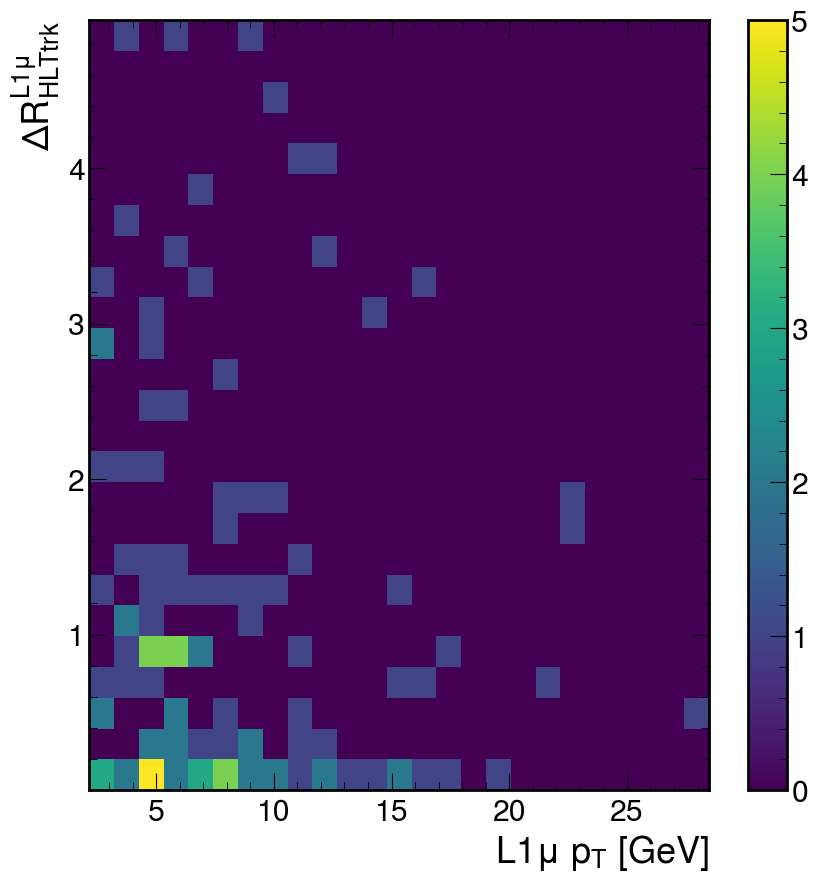

In [81]:
l1mu_hlttk_minDR = ak.firsts(ak.sort(nb_DR(l1mu, good_hlttk, ak.ArrayBuilder()).snapshot(), axis=-1), axis=-1)
_, _, _, im = plt.hist2d(ak.to_numpy(ak.flatten(l1mu.pt[event_mask])), ak.to_numpy(ak.flatten(l1mu_hlttk_minDR[event_mask])), bins=(25, 25))
plt.xlabel(r'$L1 \mu$ $p_T$ [GeV]')
plt.ylabel(r'$\Delta R^{L1 \mu}_{HLT trk}$')
plt.colorbar(im)

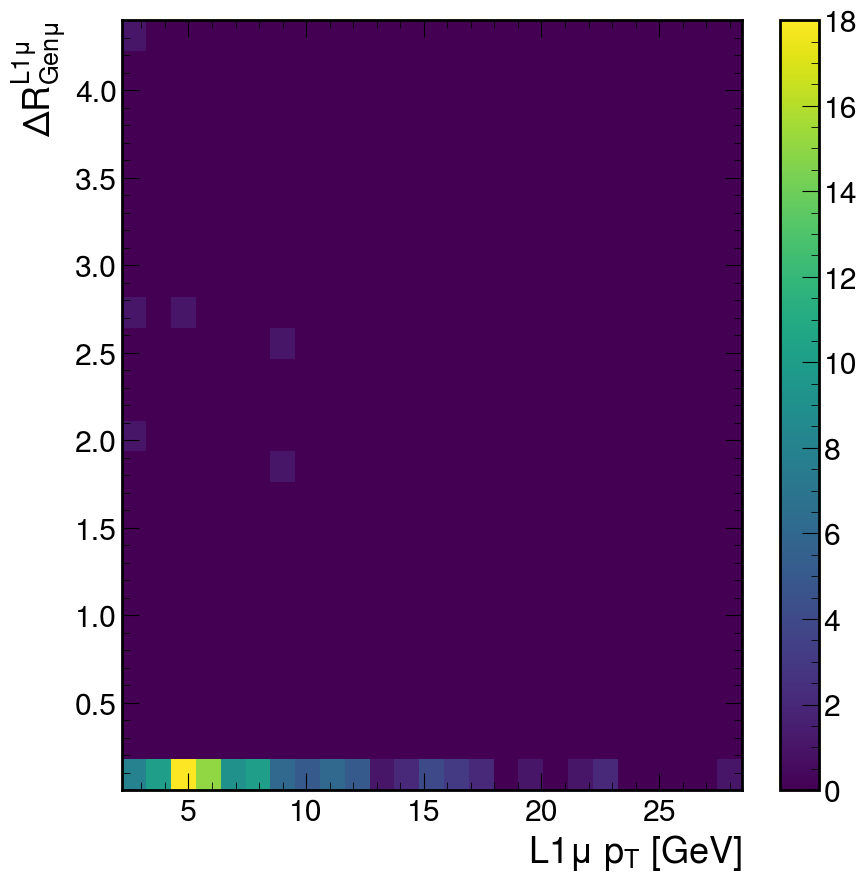

In [80]:
l1mu_genmu_minDR = ak.firsts(ak.sort(nb_DR(l1mu, genmu, ak.ArrayBuilder()).snapshot(), axis=-1), axis=-1)
_, _, _, im = plt.hist2d(ak.to_numpy(ak.flatten(l1mu.pt[event_mask])), ak.to_numpy(ak.flatten(l1mu_genmu_minDR[event_mask])), bins=(25, 25))
plt.xlabel(r'$L1 \mu$ $p_T$ [GeV]')
plt.ylabel(r'$\Delta R^{L1 \mu}_{Gen \mu}$')
plt.colorbar(im)

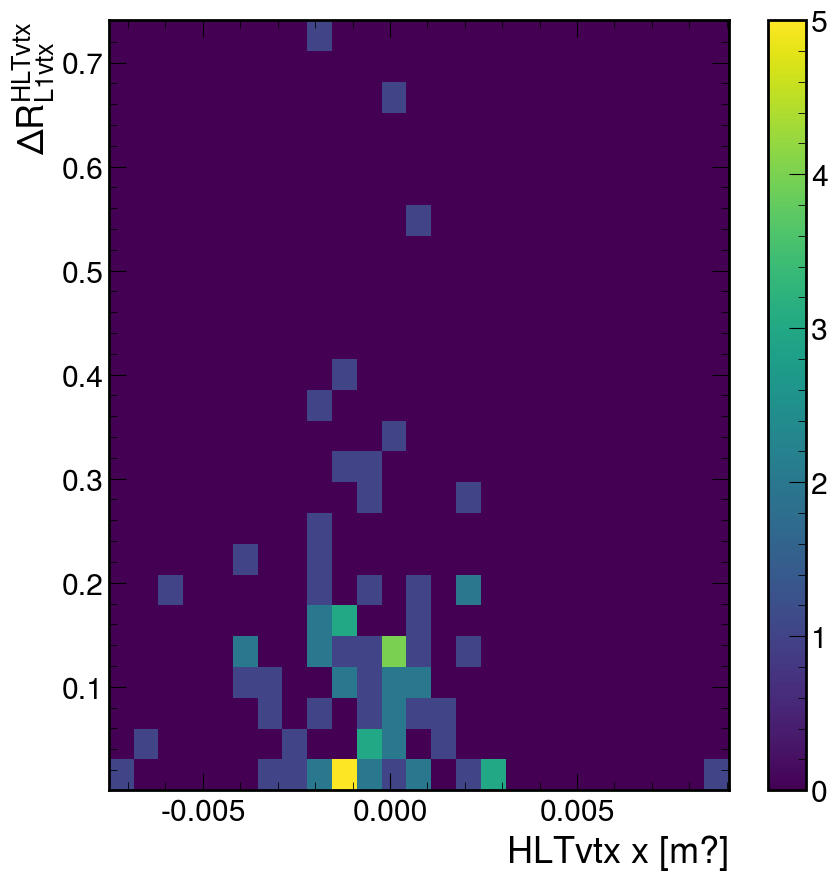

In [ ]:
hltvtx_l1vtx_minDR = ak.firsts(ak.sort(nb_Dz(good_hltvtx, good_l1vtx, ak.ArrayBuilder()).snapshot(), axis=-1), axis=-1)
_, _, _, im = plt.hist2d(ak.to_numpy(ak.flatten(good_hltvtx.x[event_mask])), ak.to_numpy(ak.flatten(hltvtx_l1vtx_minDR[event_mask])), bins=(25, 25))
plt.xlabel(r'$HLT vtx$ $x$ [m?]')
plt.ylabel(r'$\Delta z^{HLT vtx}_{L1 vtx}$')
plt.colorbar(im)

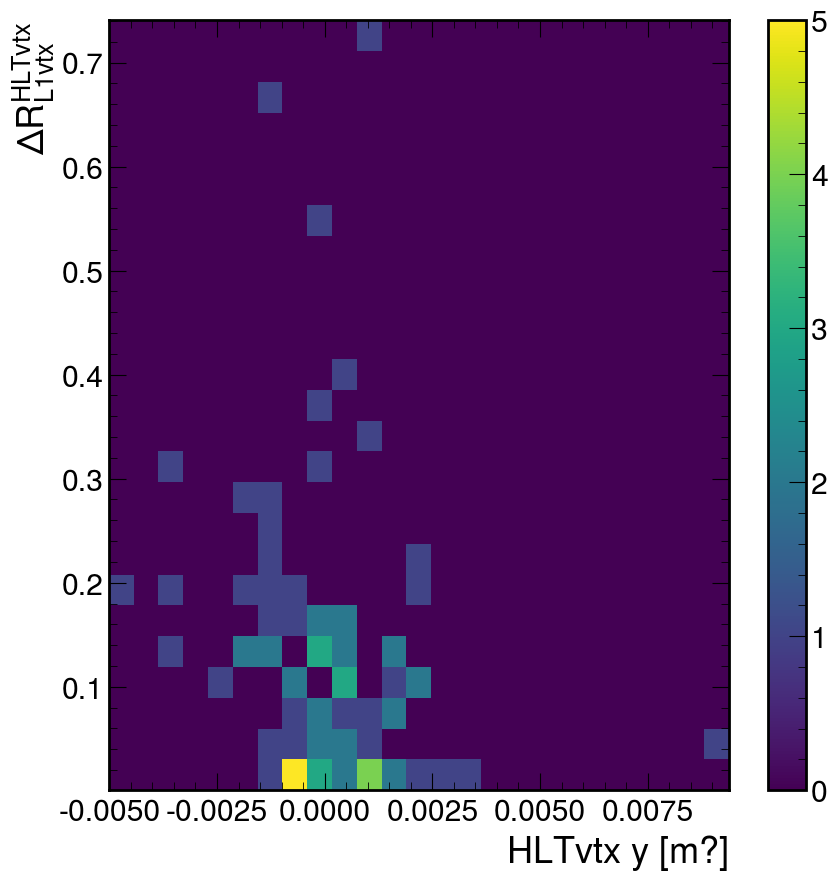

In [ ]:
hltvtx_l1vtx_minDR = ak.firsts(ak.sort(nb_Dz(good_hltvtx, good_l1vtx, ak.ArrayBuilder()).snapshot(), axis=-1), axis=-1)
_, _, _, im = plt.hist2d(ak.to_numpy(ak.flatten(good_hltvtx.y[event_mask])), ak.to_numpy(ak.flatten(hltvtx_l1vtx_minDR[event_mask])), bins=(25, 25))
plt.xlabel(r'$HLT vtx$ $y$ [m?]')
plt.ylabel(r'$\Delta z^{HLT vtx}_{L1 vtx}$')
plt.colorbar(im)

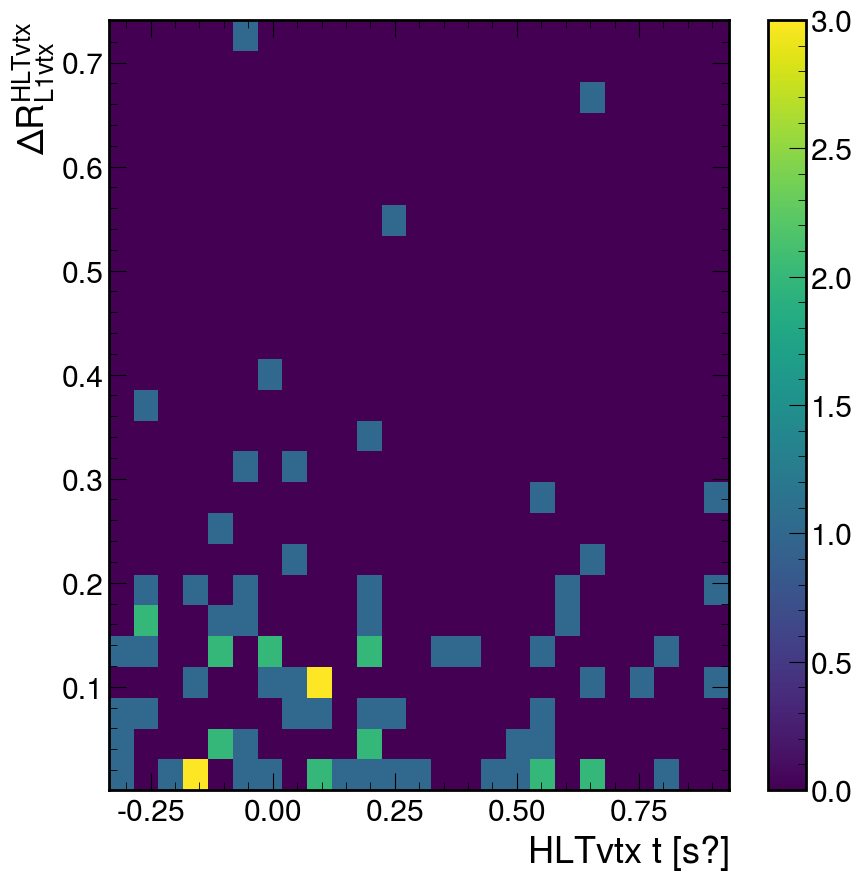

In [ ]:
hltvtx_l1vtx_minDR = ak.firsts(ak.sort(nb_Dz(good_hltvtx, good_l1vtx, ak.ArrayBuilder()).snapshot(), axis=-1), axis=-1)
_, _, _, im = plt.hist2d(ak.to_numpy(ak.flatten(good_hltvtx.t[event_mask])), ak.to_numpy(ak.flatten(hltvtx_l1vtx_minDR[event_mask])), bins=(25, 25))
plt.xlabel(r'$HLT vtx$ $t$ [s?]')
plt.ylabel(r'$\Delta z^{HLT vtx}_{L1 vtx}$')
plt.colorbar(im)

(array([   0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0., 1000.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.]),
 array([0.5 , 0.51, 0.52, 0.53, 0.54, 0.55, 0.56, 0.57, 0.58, 0.59, 0.6 ,
        0.61, 0.62, 0.63, 0.64, 0.65, 0.66, 0.67, 0.68, 0.69, 0.7 , 0.71,
        0.72, 0.73, 0.74, 0.75, 0.76, 0.77, 0.78, 0.79

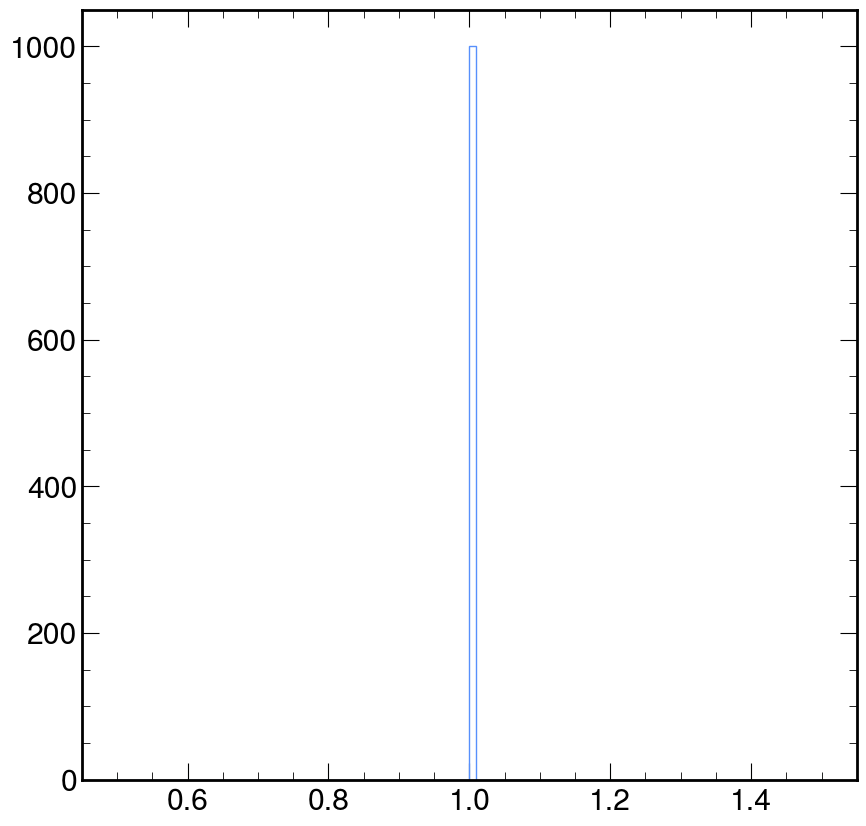

In [22]:
plt.hist(ak.num(l1vtx, axis=1), bins=100, log=False, histtype='step')

(array([890.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0., 104.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          6.]),
 array([1.  , 1.02, 1.04, 1.06, 1.08, 1.1 , 1.12, 1.14, 1.16, 1.18, 1.2 ,
        1.22, 1.24, 1.26, 1.28, 1.3 , 1.32, 1.34, 1.36, 1.38, 1.4 , 1.42,
        1.44, 1.46, 1.48, 1.5 , 1.52, 1.54, 1.56, 1.58, 1.6 , 1.62, 1.64,
        1.66, 1.68, 1.7 , 1.72, 1.74, 1.76, 1.78, 1.8 , 1.82, 1.84, 1.86,
        1.88, 1.9 , 1.

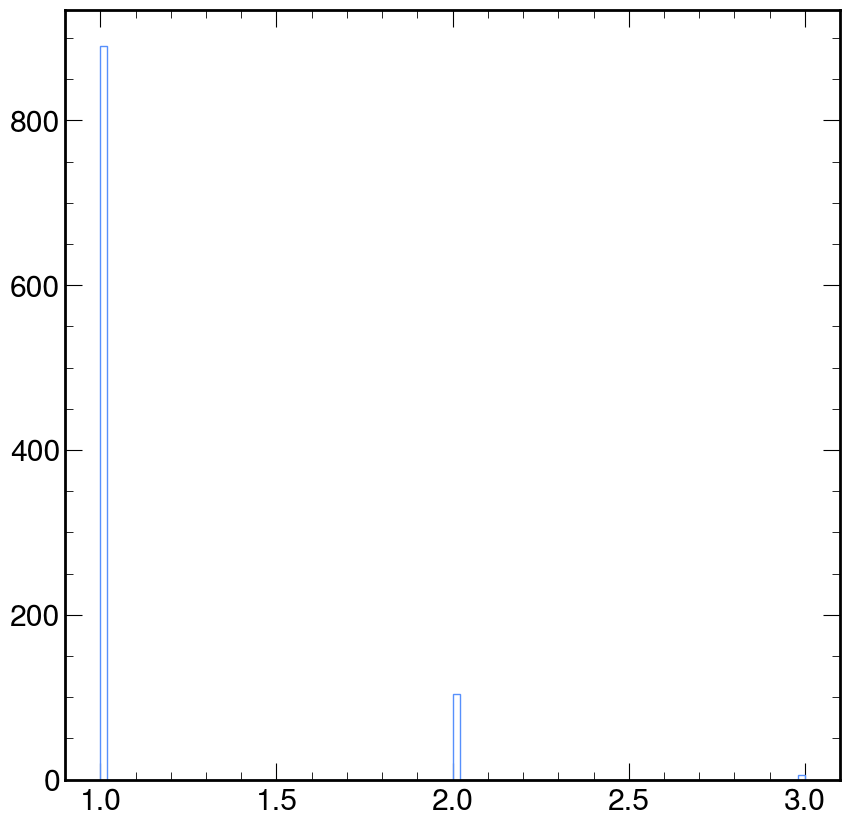

In [21]:
plt.hist(ak.num(hltvtx, axis=1), bins=100, log=False, histtype='step')

(array([4.0000e+00, 2.0000e+00, 9.0000e+00, 1.2000e+01, 1.3000e+01,
        1.6000e+01, 2.0000e+01, 4.0000e+01, 6.1000e+01, 7.4000e+01,
        1.0800e+02, 1.3700e+02, 1.5800e+02, 1.2500e+02, 1.8400e+02,
        1.8900e+02, 2.6600e+02, 2.5600e+02, 3.1000e+02, 3.0300e+02,
        2.0488e+04, 2.8200e+02, 2.3700e+02, 2.0400e+02, 2.0500e+02,
        1.9200e+02, 1.7800e+02, 1.5400e+02, 1.5800e+02, 1.2800e+02,
        1.0400e+02, 8.1000e+01, 7.5000e+01, 8.3000e+01, 8.3000e+01,
        6.8000e+01, 9.5000e+01, 9.7000e+01, 1.1900e+02, 1.1100e+02,
        1.1500e+02, 1.3200e+02, 1.2400e+02, 1.4900e+02, 1.5200e+02,
        1.5400e+02, 1.4800e+02, 1.2200e+02, 1.3000e+02, 9.4000e+01,
        1.0800e+02, 8.4000e+01, 6.4000e+01, 6.3000e+01, 5.3000e+01,
        4.0000e+01, 4.0000e+01, 3.4000e+01, 2.9000e+01, 2.3000e+01,
        2.0000e+01, 1.5000e+01, 9.0000e+00, 1.5000e+01, 1.0000e+01,
        5.0000e+00, 7.0000e+00, 6.0000e+00, 8.0000e+00, 5.0000e+00,
        1.0000e+00, 7.0000e+00, 3.0000e+00, 3.00

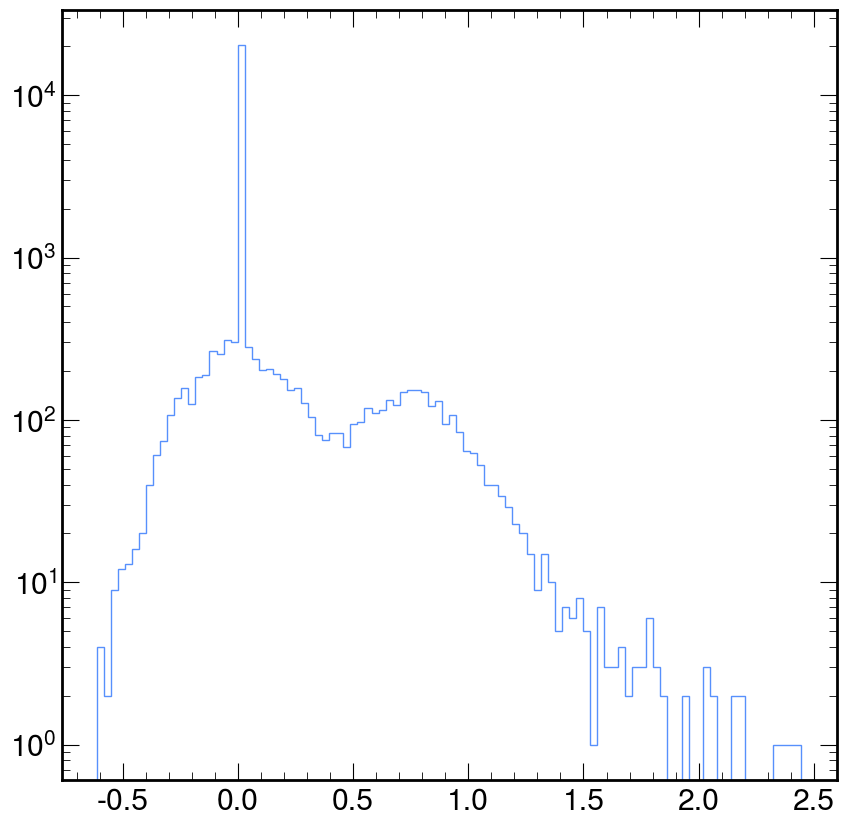

In [20]:
plt.hist(ak.flatten(hlttk['t0safe']), bins=100, log=True, histtype='step')

(array([2.0227e+04, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        3.6000e+01, 2.5000e+01, 3.8000e+01, 3.0000e+01, 2.6000e+01,
        3.3000e+01, 2.8000e+01, 2.6000e+01, 1.9000e+01, 3.8000e+01,
        4.2000e+01, 2.7000e+01, 2.7000e+01, 3.3000e+01, 3.4000e+01,
        2.6000e+01, 4.3000e+01, 3.8000e+01, 3.8000e+01, 3.3000e+01,
        2.3000e+01, 3.5000e+01, 3.8000e+01, 4.70

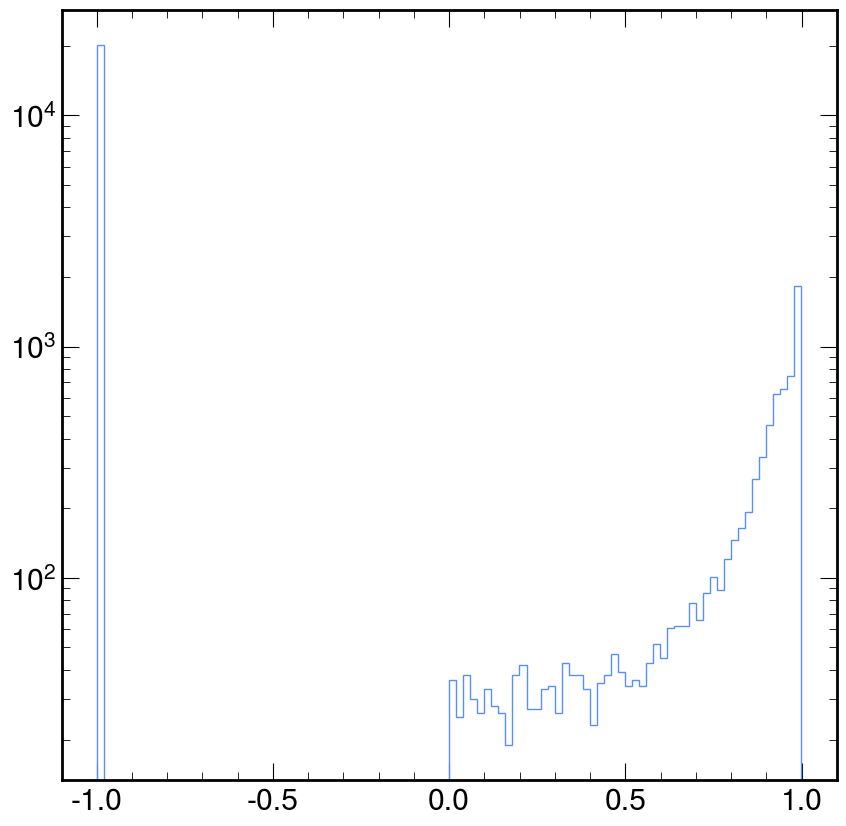

In [23]:
plt.hist(ak.flatten(hlttk['mtdQualMVA']), bins=100, log=True, histtype='step')